# Install and verify dependencies

In [1]:
!pip install mediapipe==1.0.1 -q

import mediapipe as mp
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import cv2
print("mediapipe:", mp.__version__)
print("tensorflow:", tf.__version__)
print("keras:", tf.keras.__version__)
print("numpy:", np.__version__)
print("sklearn:", sklearn.__version__)
print("cv2:", cv2.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 53.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 7.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
mediapipe: 1.0.1
tensorflow: 2.20.0
keras: 3.13.2
numpy: 2.1.3
sklearn: 1.6.1
cv2: 4.14.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# Import all required libraries

In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input, GaussianNoise
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
import tensorflow as tf

print("All imports successful")
print("TF version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)

All imports successful
TF version: 2.20.0
GPU available: True


# Define paths, explore dataset, select 70 classes and verify

In [4]:
tf.keras.backend.clear_session()
from tensorflow.keras.layers import Flatten
from sklearn.metrics import precision_recall_fscore_support

SEQUENCE_LENGTH = 20
final_selected = [
    'Hello', 'Thank you', 'How are you', 'Good Morning', 'Good night',
    'happy', 'good', 'bad', 'Pleased', 'Alright', 'cold',
    'Mother', 'Father', 'Brother', 'Sister', 'Son', 'Daughter',
    'Grandfather', 'Grandmother', 'Husband', 'Wife',
    'Doctor', 'Teacher', 'Police', 'Soldier', 'Lawyer', 'Reporter', 'Manager', 'Waiter',
    'School', 'Hospital', 'Market', 'Restaurant', 'Library', 'Temple', 'University', 'Bank',
    'Dog', 'Cat', 'Horse', 'Bird', 'Fish', 'Cow',
    'Red', 'Blue', 'Green', 'Yellow', 'Black', 'White',
    'Book', 'Pen', 'Table', 'Chair', 'Door', 'Window', 'Telephone', 'Computer',
    'Car', 'Bus', 'Train', 'Bicycle', 'Plane',
    'Morning', 'Afternoon', 'Evening', 'Today', 'Tomorrow',
    'I', 'you', 'we'
]
final_selected = [c for c in final_selected if c in set(classes)]
NUM_CLASSES = len(final_selected)
print("Classes:", NUM_CLASSES)

def extract_hand_landmarks_from_df(df):
    frames = sorted(df['frame'].unique())
    sequence = []
    for frame in frames:
        frame_df = df[df['frame'] == frame]
        landmarks = np.zeros(126)
        left = frame_df[frame_df['type'] == 'left_hand'].sort_values('landmark_index')
        right = frame_df[frame_df['type'] == 'right_hand'].sort_values('landmark_index')
        if len(left) == 21:
            for idx, row in enumerate(left.itertuples()):
                landmarks[idx*3] = row.x if not np.isnan(row.x) else 0.0
                landmarks[idx*3+1] = row.y if not np.isnan(row.y) else 0.0
                landmarks[idx*3+2] = row.z if not np.isnan(row.z) else 0.0
        if len(right) == 21:
            for idx, row in enumerate(right.itertuples()):
                landmarks[63+idx*3] = row.x if not np.isnan(row.x) else 0.0
                landmarks[63+idx*3+1] = row.y if not np.isnan(row.y) else 0.0
                landmarks[63+idx*3+2] = row.z if not np.isnan(row.z) else 0.0
        sequence.append(landmarks)
    return sequence

def normalize_wrist_relative(landmarks_126):
    lm = landmarks_126.copy()
    left = lm[:63].reshape(21, 3)
    right = lm[63:].reshape(21, 3)
    if np.count_nonzero(left) > 0:
        left = left - left[0].copy()
        left = left / (np.max(np.abs(left)) + 1e-8)
    if np.count_nonzero(right) > 0:
        right = right - right[0].copy()
        right = right / (np.max(np.abs(right)) + 1e-8)
    lm[:63] = left.flatten()
    lm[63:] = right.flatten()
    return lm

def pad_or_truncate(sequence, length=SEQUENCE_LENGTH):
    if len(sequence) >= length:
        indices = np.linspace(0, len(sequence)-1, length, dtype=int)
        return np.array([sequence[i] for i in indices])
    padded = np.array(sequence)
    return np.vstack([padded, np.zeros((length - len(padded), 126))])

X, y = [], []
for label_idx, cls in enumerate(final_selected):
    cls_path = os.path.join(BASE_PATH, cls)
    for file in [f for f in os.listdir(cls_path) if f.endswith('.parquet')]:
        seq = extract_hand_landmarks_from_df(pd.read_parquet(os.path.join(cls_path, file)))
        if len(seq) == 0:
            continue
        X.append(pad_or_truncate([normalize_wrist_relative(lm) for lm in seq]))
        y.append(label_idx)
X, y = np.array(X), np.array(y)
print("X:", X.shape, "| NaN:", np.isnan(X).sum())

X_mean = X.mean(axis=(0, 1), keepdims=True)
X_std = X.std(axis=(0, 1), keepdims=True)
X_norm = np.nan_to_num((X - X_mean) / (X_std + 1e-8))
y_cat = to_categorical(y, num_classes=NUM_CLASSES)

X_train, X_test, y_train, y_test = train_test_split(
    X_norm, y_cat, test_size=0.2, random_state=42, stratify=y)

def augment_sequence_heavy(s):
    return [s + np.random.normal(0, 0.03, s.shape),
            s + np.random.normal(0, 0.05, s.shape),
            s * np.random.uniform(0.88, 1.12),
            s * np.random.uniform(0.80, 1.20),
            np.roll(s, shift=np.random.randint(-3, 3), axis=0),
            s * np.random.binomial(1, 0.85, s.shape)]

X_aug, y_aug = list(X_train), list(y_train)
for i in range(len(X_train)):
    for a in augment_sequence_heavy(X_train[i]):
        X_aug.append(a); y_aug.append(y_train[i])
X_aug, y_aug = np.array(X_aug), np.array(y_aug)

cw = compute_class_weight('balanced', classes=np.unique(np.argmax(y_aug, axis=1)), y=np.argmax(y_aug, axis=1))
cw_dict = dict(enumerate(cw))
print("Train:", X_train.shape, "| Augmented:", X_aug.shape, "| Test:", X_test.shape)

mlp = Sequential([
    Input(shape=(20, 126)),
    Flatten(),
    GaussianNoise(0.12),
    Dense(512, activation='relu'), BatchNormalization(), Dropout(0.45),
    Dense(256, activation='relu'), BatchNormalization(), Dropout(0.45),
    Dense(128, activation='relu'), Dropout(0.35),
    Dense(NUM_CLASSES, activation='softmax')
])
mlp.compile(optimizer=tf.keras.optimizers.Adam(0.001),
            loss='categorical_crossentropy', metrics=['accuracy'])

hist = mlp.fit(X_aug, y_aug, validation_data=(X_test, y_test), epochs=250, batch_size=32,
               class_weight=cw_dict, verbose=2,
               callbacks=[
                   EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True),
                   ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15, min_lr=1e-7),
                   ModelCheckpoint('/kaggle/working/best_mlp_model.keras', monitor='val_accuracy', save_best_only=True)])

best = tf.keras.models.load_model('/kaggle/working/best_mlp_model.keras')
tr = np.argmax(best.predict(X_train, verbose=0), axis=1)
te = np.argmax(best.predict(X_test, verbose=0), axis=1)
yt_tr, yt_te = np.argmax(y_train, axis=1), np.argmax(y_test, axis=1)
_, _, f1, _ = precision_recall_fscore_support(yt_te, te, labels=list(range(NUM_CLASSES)), zero_division=0)

best.save('/kaggle/working/isl_mlp_model_70.keras')
np.save('/kaggle/working/X_mlp_mean.npy', X_mean)
np.save('/kaggle/working/X_mlp_std.npy', X_std)
np.save('/kaggle/working/label_classes.npy', np.array(final_selected))

print("\n===== FINAL RESULT =====")
print(f"Epochs run:     {len(hist.history['loss'])}")
print(f"Train accuracy: {np.mean(tr == yt_tr)*100:.4f}%")
print(f"Test accuracy:  {np.mean(te == yt_te)*100:.4f}%")
print(f"Classes with F1 >= 0.75: {int((f1 >= 0.75).sum())}/{NUM_CLASSES}")
print("Weak classes:", [final_selected[i] for i in range(NUM_CLASSES) if f1[i] < 0.75])

Classes: 70
X: (1293, 20, 126) | NaN: 0
Train: (1034, 20, 126) | Augmented: (7238, 20, 126) | Test: (259, 20, 126)
Epoch 1/250
227/227 - 10s - 43ms/step - accuracy: 0.2053 - loss: 3.2746 - val_accuracy: 0.5290 - val_loss: 1.6569 - learning_rate: 0.0010
Epoch 2/250
227/227 - 1s - 3ms/step - accuracy: 0.5099 - loss: 1.6745 - val_accuracy: 0.6602 - val_loss: 1.1533 - learning_rate: 0.0010
Epoch 3/250
227/227 - 1s - 3ms/step - accuracy: 0.6318 - loss: 1.1839 - val_accuracy: 0.7452 - val_loss: 0.9413 - learning_rate: 0.0010
Epoch 4/250
227/227 - 1s - 3ms/step - accuracy: 0.7031 - loss: 0.9008 - val_accuracy: 0.7259 - val_loss: 0.9272 - learning_rate: 0.0010
Epoch 5/250
227/227 - 1s - 3ms/step - accuracy: 0.7633 - loss: 0.7345 - val_accuracy: 0.7336 - val_loss: 0.8521 - learning_rate: 0.0010
Epoch 6/250
227/227 - 1s - 3ms/step - accuracy: 0.8113 - loss: 0.5938 - val_accuracy: 0.7297 - val_loss: 0.8340 - learning_rate: 0.0010
Epoch 7/250
227/227 - 1s - 4ms/step - accuracy: 0.8317 - loss: 0.52

# Evaluate on test data with the exact per-class metrics

Class                 Precision     Recall         F1  Support
--------------------------------------------------------------
Hello                  0.800000   1.000000   0.888889        4
Thank you              1.000000   0.750000   0.857143        4
How are you            1.000000   1.000000   1.000000        4
Good Morning           1.000000   0.500000   0.666667        4
Good night             0.800000   1.000000   0.888889        4
happy                  1.000000   0.750000   0.857143        4
good                   0.666667   1.000000   0.800000        4
bad                    1.000000   0.750000   0.857143        4
Pleased                1.000000   1.000000   1.000000        4
Alright                0.666667   1.000000   0.800000        4
cold                   0.800000   1.000000   0.888889        4
Mother                 0.800000   1.000000   0.888889        4
Father                 1.000000   1.000000   1.000000        4
Brother                1.000000   0.500000   0.666667  

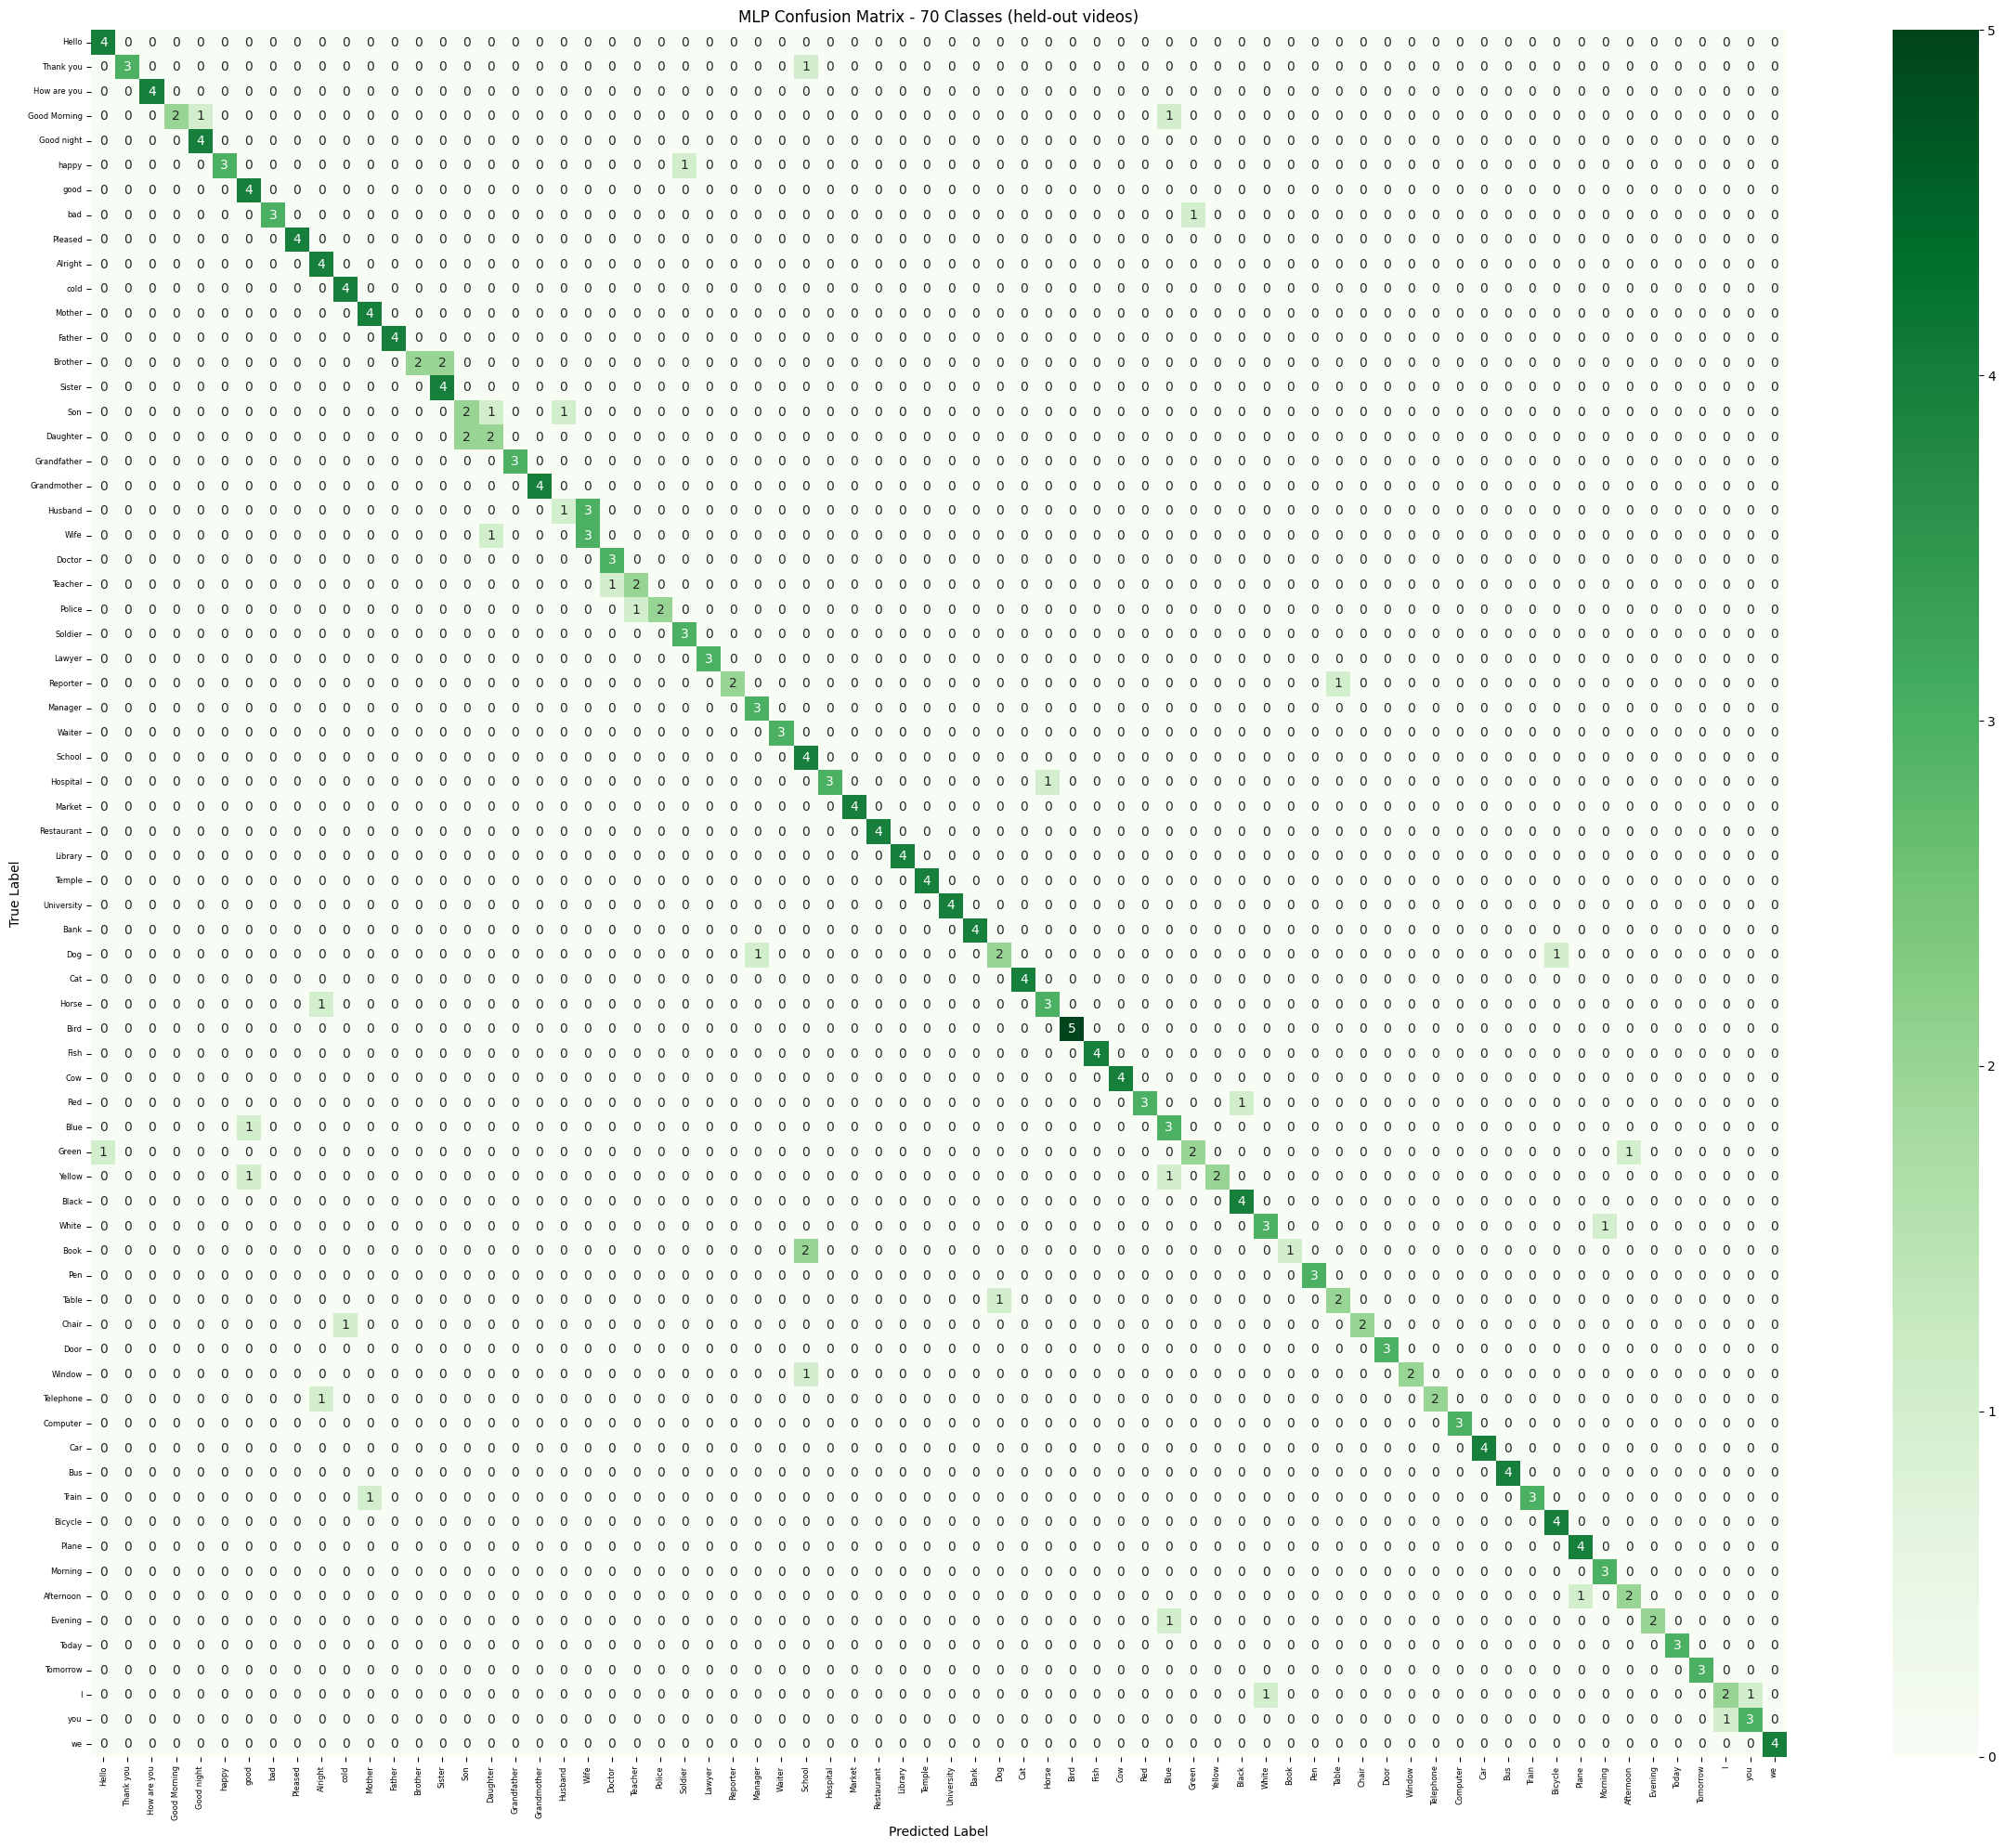


Most confused pairs (true -> predicted, count):
  Husband         -> Wife            3
  Daughter        -> Son             2
  Brother         -> Sister          2
  Book            -> School          2
  you             -> I               1
  happy           -> Soldier         1
  bad             -> Green           1
  Yellow          -> good            1
  Yellow          -> Blue            1
  Window          -> School          1
  Wife            -> Daughter        1
  White           -> Morning         1
  Train           -> Mother          1
  Thank you       -> School          1
  Telephone       -> Alright         1


In [5]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
import pandas as pd

best = tf.keras.models.load_model('/kaggle/working/isl_mlp_model_70.keras')

y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(best.predict(X_test, verbose=0), axis=1)
y_true_tr = np.argmax(y_train, axis=1)
y_pred_tr = np.argmax(best.predict(X_train, verbose=0), axis=1)

precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0)

print(f"{'Class':<20} {'Precision':>10} {'Recall':>10} {'F1':>10} {'Support':>8}")
print("-" * 62)
for i, cls in enumerate(final_selected):
    print(f"{cls:<20} {precision[i]:>10.6f} {recall[i]:>10.6f} {f1[i]:>10.6f} {support[i]:>8}")
print("-" * 62)

print(f"\nTrain accuracy (original train videos): {np.mean(y_pred_tr == y_true_tr)*100:.6f}%")
print(f"Test accuracy  (held-out videos):       {np.mean(y_pred == y_true)*100:.6f}%")
print(f"Macro precision: {precision.mean():.6f}")
print(f"Macro recall:    {recall.mean():.6f}")
print(f"Macro F1:        {f1.mean():.6f}")
print(f"Test samples:    {len(y_true)}")
print(f"Classes with F1 >= 0.75: {int((f1 >= 0.75).sum())}/{NUM_CLASSES}")

report_df = pd.DataFrame({'class': final_selected, 'precision': precision,
                          'recall': recall, 'f1': f1, 'support': support})
report_df.to_csv('/kaggle/working/mlp_classification_report.csv', index=False)

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(24, 20))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=final_selected,
            yticklabels=final_selected, cmap='Greens')
plt.title('MLP Confusion Matrix - 70 Classes (held-out videos)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.savefig('/kaggle/working/mlp_confusion_matrix_70.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nMost confused pairs (true -> predicted, count):")
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(off[i, j], final_selected[i], final_selected[j])
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0]
for count, t, p in sorted(pairs, reverse=True)[:15]:
    print(f"  {t:<15} -> {p:<15} {count}")

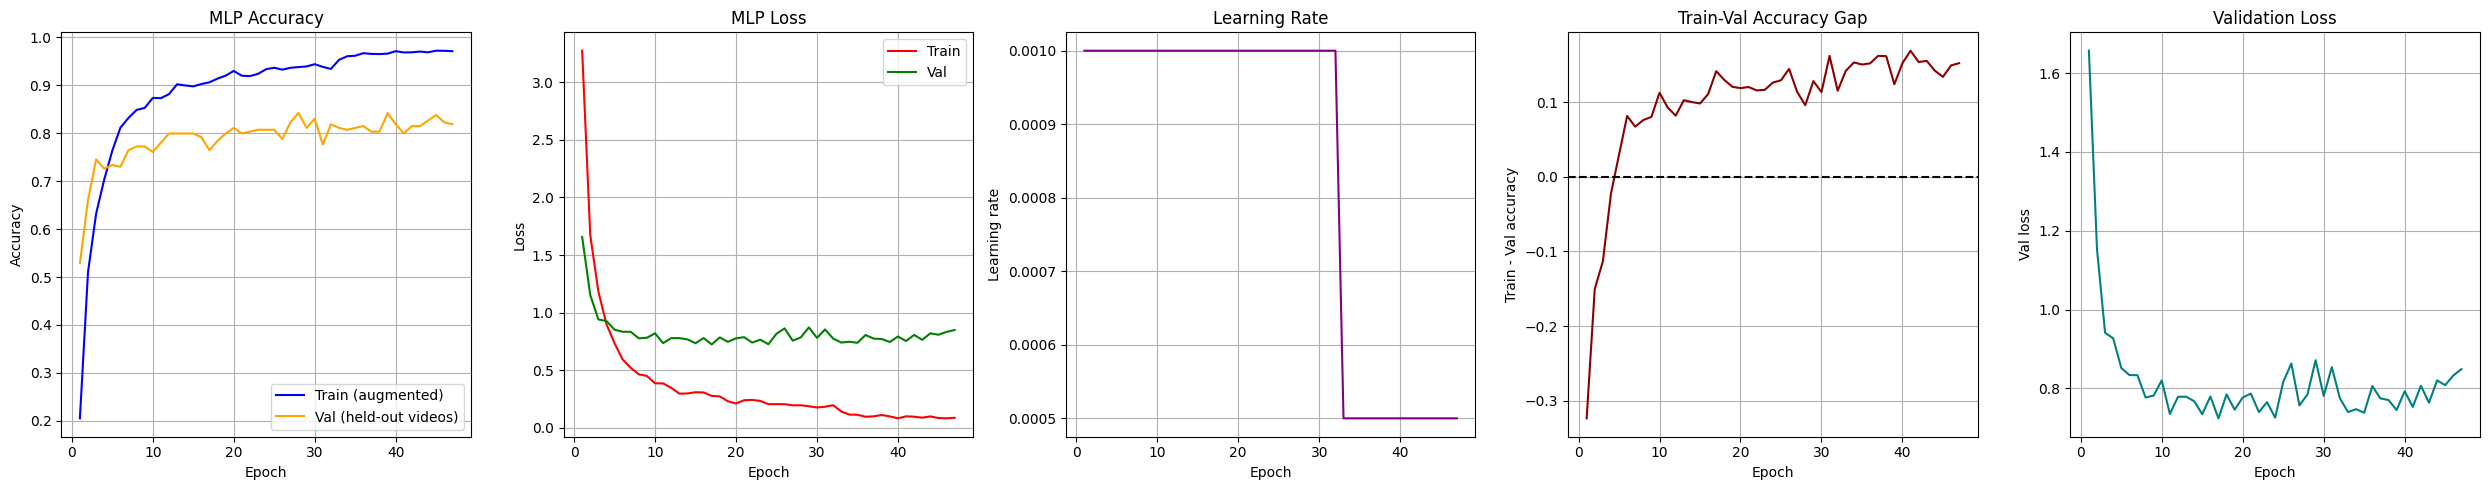

Epochs run: 47
Best val accuracy: 84.1699% at epoch 28
Lowest val loss:   0.7243 at epoch 17
Final epoch: train acc 97.08% | val acc 81.85%
Saved: ['mlp_graph_00_all_training.png', 'mlp_graph_01_accuracy.png', 'mlp_graph_02_loss.png', 'mlp_graph_03_lr.png', 'mlp_graph_04_gap.png', 'mlp_graph_05_val_loss.png']


In [6]:
h = hist.history
ep = np.arange(1, len(h['loss']) + 1)
tr_acc, va_acc = np.array(h['accuracy']), np.array(h['val_accuracy'])
tr_loss, va_loss = np.array(h['loss']), np.array(h['val_loss'])
lr = np.array(h['learning_rate'])

def d_acc(ax):
    ax.plot(ep, tr_acc, color='blue', label='Train (augmented)')
    ax.plot(ep, va_acc, color='orange', label='Val (held-out videos)')
    ax.set_ylabel('Accuracy'); ax.legend()

def d_loss(ax):
    ax.plot(ep, tr_loss, color='red', label='Train')
    ax.plot(ep, va_loss, color='green', label='Val')
    ax.set_ylabel('Loss'); ax.legend()

def d_lr(ax):
    ax.plot(ep, lr, color='purple'); ax.set_ylabel('Learning rate')

def d_gap(ax):
    ax.plot(ep, tr_acc - va_acc, color='darkred')
    ax.axhline(0, color='black', linestyle='--'); ax.set_ylabel('Train - Val accuracy')

def d_vloss(ax):
    ax.plot(ep, va_loss, color='teal'); ax.set_ylabel('Val loss')

panels = [
    ('mlp_graph_01_accuracy', 'MLP Accuracy', d_acc),
    ('mlp_graph_02_loss', 'MLP Loss', d_loss),
    ('mlp_graph_03_lr', 'Learning Rate', d_lr),
    ('mlp_graph_04_gap', 'Train-Val Accuracy Gap', d_gap),
    ('mlp_graph_05_val_loss', 'Validation Loss', d_vloss),
]

for fname, title, fn in panels:
    fig, ax = plt.subplots(figsize=(6, 4))
    fn(ax); ax.set_title(title); ax.set_xlabel('Epoch'); ax.grid(True)
    fig.savefig(f'/kaggle/working/{fname}.png', dpi=150, bbox_inches='tight')
    plt.close(fig)

fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for ax, (fname, title, fn) in zip(axes, panels):
    fn(ax); ax.set_title(title); ax.set_xlabel('Epoch'); ax.grid(True)
plt.tight_layout()
plt.savefig('/kaggle/working/mlp_graph_00_all_training.png', dpi=150, bbox_inches='tight')
plt.show()

print("Epochs run:", len(ep))
print(f"Best val accuracy: {va_acc.max()*100:.4f}% at epoch {va_acc.argmax()+1}")
print(f"Lowest val loss:   {va_loss.min():.4f} at epoch {va_loss.argmin()+1}")
print(f"Final epoch: train acc {tr_acc[-1]*100:.2f}% | val acc {va_acc[-1]*100:.2f}%")
print("Saved:", sorted(f for f in os.listdir('/kaggle/working') if f.startswith('mlp_graph')))

In [7]:
best = tf.keras.models.load_model('/kaggle/working/isl_mlp_model_70.keras')

rng = np.random.default_rng(7)
y_true = np.argmax(y_test, axis=1)

print("=== 10 random held-out videos ===\n")
correct = 0
for idx in rng.choice(len(X_test), 10, replace=False):
    probs = best.predict(X_test[idx:idx+1], verbose=0)[0]
    pred = int(np.argmax(probs))
    top3 = np.argsort(probs)[::-1][:3]
    ok = pred == y_true[idx]
    correct += ok
    print(f"{'OK ' if ok else 'BAD'} True: {final_selected[y_true[idx]]:<14} "
          f"Pred: {final_selected[pred]:<14} Conf: {probs[pred]*100:.4f}%")
    print("     Top3:", [(final_selected[i], round(float(probs[i])*100, 4)) for i in top3])
print(f"\nCorrect: {correct}/10")

print("\n=== One held-out video per class (all 70) ===\n")
wrong, confs_ok, confs_bad = [], [], []
for c in range(NUM_CLASSES):
    ids = np.where(y_true == c)[0]
    if len(ids) == 0:
        continue
    probs = best.predict(X_test[ids[0]:ids[0]+1], verbose=0)[0]
    pred = int(np.argmax(probs))
    if pred == c:
        confs_ok.append(probs[pred] * 100)
    else:
        confs_bad.append(probs[pred] * 100)
        wrong.append((final_selected[c], final_selected[pred], round(float(probs[pred])*100, 2)))

print(f"Right: {len(confs_ok)}/{NUM_CLASSES}")
print("Wrong (true -> predicted, confidence%):")
for w in wrong:
    print("  ", w)
print(f"\nAvg confidence when right: {np.mean(confs_ok):.2f}%")
print(f"Avg confidence when wrong: {np.mean(confs_bad):.2f}%" if confs_bad else "No wrong ones.")

=== 10 random held-out videos ===

OK  True: Hospital       Pred: Hospital       Conf: 99.9999%
     Top3: [('Hospital', 99.9999), ('Wife', 0.0001), ('Bank', 0.0)]
OK  True: Sister         Pred: Sister         Conf: 66.0843%
     Top3: [('Sister', 66.0843), ('Brother', 29.6101), ('Plane', 3.4803)]
OK  True: White          Pred: White          Conf: 99.8861%
     Top3: [('White', 99.8861), ('Train', 0.0485), ('Red', 0.0414)]
OK  True: we             Pred: we             Conf: 70.1052%
     Top3: [('we', 70.1052), ('Car', 28.249), ('Mother', 0.7868)]
OK  True: Computer       Pred: Computer       Conf: 99.9292%
     Top3: [('Computer', 99.9292), ('Bird', 0.0231), ('Bicycle', 0.0193)]
OK  True: Temple         Pred: Temple         Conf: 99.9913%
     Top3: [('Temple', 99.9913), ('Hospital', 0.0086), ('cold', 0.0001)]
OK  True: Temple         Pred: Temple         Conf: 99.9997%
     Top3: [('Temple', 99.9997), ('Hospital', 0.0003), ('cold', 0.0)]
BAD True: White          Pred: Morning       

In [8]:
rows = []
for cls in final_selected:
    cls_path = os.path.join(BASE_PATH, cls)
    left_frac, right_frac = [], []
    for file in [f for f in os.listdir(cls_path) if f.endswith('.parquet')]:
        seq = np.array(extract_hand_landmarks_from_df(pd.read_parquet(os.path.join(cls_path, file))))
        n = len(seq)
        mid = seq[int(n * 0.2):int(n * 0.8)]
        if len(mid) == 0:
            continue
        left_frac.append(np.mean(np.count_nonzero(mid[:, :63], axis=1) > 0))
        right_frac.append(np.mean(np.count_nonzero(mid[:, 63:], axis=1) > 0))
    l, r = float(np.mean(left_frac)), float(np.mean(right_frac))
    usage = 'both' if (l > 0.5 and r > 0.5) else 'right' if r > 0.5 else 'left' if l > 0.5 else 'none'
    rows.append({'class': cls, 'videos': len(left_frac), 'left_present': l,
                 'right_present': r, 'detected_hands': usage})

hand_df = pd.DataFrame(rows)
hand_df.to_csv('/kaggle/working/hand_usage_per_class.csv', index=False)

print(f"{'Class':<16}{'Videos':>7}{'Left':>9}{'Right':>9}  Detected")
print("-" * 52)
for _, r in hand_df.iterrows():
    print(f"{r['class']:<16}{r['videos']:>7}{r['left_present']:>9.3f}{r['right_present']:>9.3f}  {r['detected_hands']}")

print("\nSummary:")
print(hand_df['detected_hands'].value_counts().to_string())

ref_path = '/kaggle/working/reference_landmarks_70.json'
if os.path.exists(ref_path):
    ref = json.load(open(ref_path))
    print("\nReference file found. Classes where the reference has a hand that is detected in <50% of videos:")
    for _, r in hand_df.iterrows():
        v = np.array(ref[r['class']])
        has_l, has_r = np.count_nonzero(v[:63]) > 0, np.count_nonzero(v[63:]) > 0
        if (has_l and r['left_present'] <= 0.5) or (has_r and r['right_present'] <= 0.5):
            print(f"  {r['class']:<16} ref has L={has_l} R={has_r} | detected L={r['left_present']:.2f} R={r['right_present']:.2f}")
else:
    print("\nreference_landmarks_70.json is not in this notebook (it was made in the LSTM notebook). Skipping that comparison.")

Class            Videos     Left    Right  Detected
----------------------------------------------------
Hello                21    1.000    0.736  both
Thank you            21    0.756    0.773  both
How are you          21    0.752    0.784  both
Good Morning         21    1.000    0.768  both
Good night           21    1.000    0.714  both
happy                21    0.680    0.713  both
good                 21    0.982    0.835  both
bad                  21    0.996    0.772  both
Pleased              21    1.000    0.694  both
Alright              21    0.700    0.749  both
cold                 20    0.740    0.741  both
Mother               20    0.904    0.691  both
Father               20    0.729    0.806  both
Brother              21    0.895    0.763  both
Sister               20    0.915    0.712  both
Son                  20    0.749    0.816  both
Daughter             20    0.703    0.820  both
Grandfather          17    0.804    0.776  both
Grandmother          17    0.88

In [9]:
best = tf.keras.models.load_model('/kaggle/working/isl_mlp_model_70.keras')
y_true = np.argmax(y_test, axis=1)

# what an absent hand looks like after the same normalization used in training
zero_val = (0.0 - X_mean) / (X_std + 1e-8)          # shape (1, 1, 126)
LEFT, RIGHT = slice(0, 63), slice(63, 126)

def blank(X, sl):
    Xm = X.copy()
    Xm[:, :, sl] = zero_val[:, :, sl]
    return Xm

def preds(Xm):
    return np.argmax(best.predict(Xm, verbose=0), axis=1)

def per_class(p):
    return np.array([np.mean(p[y_true == c] == c) for c in range(NUM_CLASSES)])

p_base = preds(X_test)
p_noL = preds(blank(X_test, LEFT))                  # only the right hand present
p_noR = preds(blank(X_test, RIGHT))                 # only the left hand present
p_none = preds(blank(blank(X_test, LEFT), RIGHT))   # no hands at all (sanity check)

print(f"Both hands (as trained):        {np.mean(p_base == y_true)*100:.4f}%")
print(f"Left blanked (right only):      {np.mean(p_noL == y_true)*100:.4f}%")
print(f"Right blanked (left only):      {np.mean(p_noR == y_true)*100:.4f}%")
print(f"Both blanked (sanity check):    {np.mean(p_none == y_true)*100:.4f}%")

base_c = per_class(p_base)
for name, p in (("right only", p_noL), ("left only", p_noR)):
    drop = base_c - per_class(p)
    worst = np.argsort(drop)[::-1][:8]
    print(f"\nBiggest per-class drops when showing {name}:")
    for i in worst:
        print(f"  {final_selected[i]:<14} {base_c[i]*100:5.1f}% -> {per_class(p)[i]*100:5.1f}%")

Both hands (as trained):        84.1699%
Left blanked (right only):      38.6100%
Right blanked (left only):      16.2162%
Both blanked (sanity check):    1.1583%

Biggest per-class drops when showing right only:
  we             100.0% ->   0.0%
  Cat            100.0% ->   0.0%
  Fish           100.0% ->   0.0%
  Bus            100.0% ->   0.0%
  Computer       100.0% ->   0.0%
  Car            100.0% ->   0.0%
  Alright        100.0% ->   0.0%
  cold           100.0% ->   0.0%

Biggest per-class drops when showing left only:
  Today          100.0% ->   0.0%
  Tomorrow       100.0% ->   0.0%
  Bus            100.0% ->   0.0%
  Car            100.0% ->   0.0%
  Plane          100.0% ->   0.0%
  Bicycle        100.0% ->   0.0%
  Sister         100.0% ->   0.0%
  Father         100.0% ->   0.0%


In [10]:
tf.keras.backend.clear_session()
old = tf.keras.models.load_model('/kaggle/working/isl_mlp_model_70.keras')

zero_val = (0.0 - X_mean) / (X_std + 1e-8)            # (1,1,126)
perm = np.r_[63:126, 0:63]
y_true = np.argmax(y_test, axis=1)

def swap_slots(Xn):
    raw = Xn * (X_std + 1e-8) + X_mean
    raw = raw[:, :, perm]
    return (raw - X_mean) / (X_std + 1e-8)

def blank(Xn, sl):
    Xo = Xn.copy()
    Xo[:, :, sl] = zero_val[:, :, sl]
    return Xo

LEFT, RIGHT = slice(0, 63), slice(63, 126)

def evaluate(model, name):
    res = {}
    for label, Xc in (("both hands", X_test), ("right only", blank(X_test, LEFT)),
                      ("left only", blank(X_test, RIGHT)), ("slots swapped", swap_slots(X_test))):
        p = np.argmax(model.predict(Xc, verbose=0), axis=1)
        res[label] = np.mean(p == y_true) * 100
    print(f"{name}: " + " | ".join(f"{k} {v:.2f}%" for k, v in res.items()))
    return res

rng = np.random.default_rng(0)
def hand_aug(X):
    Xo = X.copy()
    r = rng.random(len(Xo))
    for i in range(len(Xo)):
        if r[i] < 0.25:
            Xo[i, :, LEFT] = zero_val[0, :, LEFT]
        elif r[i] < 0.50:
            Xo[i, :, RIGHT] = zero_val[0, :, RIGHT]
        elif r[i] < 0.60:
            Xo[i] = swap_slots(Xo[i:i+1])[0]
    return Xo

X_aug_h = hand_aug(X_aug)
print("Training samples:", X_aug_h.shape)

new = Sequential([
    Input(shape=(20, 126)), Flatten(), GaussianNoise(0.12),
    Dense(512, activation='relu'), BatchNormalization(), Dropout(0.45),
    Dense(256, activation='relu'), BatchNormalization(), Dropout(0.45),
    Dense(128, activation='relu'), Dropout(0.35),
    Dense(NUM_CLASSES, activation='softmax')
])
new.compile(optimizer=tf.keras.optimizers.Adam(0.001),
            loss='categorical_crossentropy', metrics=['accuracy'])
new.fit(X_aug_h, y_aug, validation_data=(X_test, y_test), epochs=150, batch_size=32,
        class_weight=cw_dict, verbose=2,
        callbacks=[EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True),
                   ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=12, min_lr=1e-7),
                   ModelCheckpoint('/kaggle/working/isl_mlp_model_70_handaug.keras',
                                   monitor='val_accuracy', save_best_only=True)])

new = tf.keras.models.load_model('/kaggle/working/isl_mlp_model_70_handaug.keras')
print("\n===== FINAL RESULT =====")
r_old = evaluate(old, "Old model     ")
r_new = evaluate(new, "Hand-aug model")

Training samples: (7238, 20, 126)
Epoch 1/150
227/227 - 9s - 38ms/step - accuracy: 0.0687 - loss: 4.2249 - val_accuracy: 0.3320 - val_loss: 2.5717 - learning_rate: 0.0010
Epoch 2/150
227/227 - 1s - 4ms/step - accuracy: 0.1947 - loss: 3.2187 - val_accuracy: 0.4826 - val_loss: 1.7653 - learning_rate: 0.0010
Epoch 3/150
227/227 - 1s - 4ms/step - accuracy: 0.2834 - loss: 2.6948 - val_accuracy: 0.5290 - val_loss: 1.4581 - learning_rate: 0.0010
Epoch 4/150
227/227 - 1s - 4ms/step - accuracy: 0.3625 - loss: 2.3180 - val_accuracy: 0.6100 - val_loss: 1.2769 - learning_rate: 0.0010
Epoch 5/150
227/227 - 1s - 4ms/step - accuracy: 0.4116 - loss: 2.0818 - val_accuracy: 0.6409 - val_loss: 1.1907 - learning_rate: 0.0010
Epoch 6/150
227/227 - 1s - 4ms/step - accuracy: 0.4545 - loss: 1.8930 - val_accuracy: 0.7104 - val_loss: 0.9613 - learning_rate: 0.0010
Epoch 7/150
227/227 - 1s - 3ms/step - accuracy: 0.5014 - loss: 1.7207 - val_accuracy: 0.7104 - val_loss: 0.9677 - learning_rate: 0.0010
Epoch 8/150
2

In [11]:
tf.keras.backend.clear_session()
from sklearn.model_selection import train_test_split

MODEL_PATH = '/kaggle/working/isl_mlp_model_70_handaug.keras'
mlp = tf.keras.models.load_model(MODEL_PATH)

idx = np.arange(len(X))
tr_idx, te_idx = train_test_split(idx, test_size=0.2, random_state=42, stratify=y)
if not np.allclose(X_norm[te_idx], X_test):
    raise RuntimeError("Split not reproduced; stop here and tell me.")
y_tr, y_te = y[tr_idx], y[te_idx]
print("Split reproduced. Train videos:", len(tr_idx), "| Test videos:", len(te_idx))

# reference shape per class from TRAIN videos only (wrist-relative, middle frames)
ref = np.zeros((NUM_CLASSES, 2, 21, 3)); ref_present = np.zeros((NUM_CLASSES, 2), bool)
for c in range(NUM_CLASSES):
    frames = X[tr_idx[y_tr == c]][:, 4:16, :].reshape(-1, 126)
    for h in range(2):
        sl = frames[:, h*63:(h+1)*63]
        present = np.count_nonzero(sl, axis=1) > 0
        if present.mean() > 0.5:
            ref[c, h] = np.median(sl[present], axis=0).reshape(21, 3)
            ref_present[c, h] = True
print("Classes with reference hands (left, right):",
      int(ref_present[:, 0].sum()), int(ref_present[:, 1].sum()))

def hand_dist(a, b):
    return np.mean(np.linalg.norm(a - b, axis=1))

def frame_dist(frame, c):
    u = [frame[:63].reshape(21, 3), frame[63:].reshape(21, 3)]
    up = [np.count_nonzero(h) > 0 for h in u]
    best = np.inf
    for pr in ((0, 1), (1, 0)):                      # left/right agnostic
        ds = [hand_dist(u[i], ref[c, pr[i]]) for i in range(2) if up[i] and ref_present[c, pr[i]]]
        if ds:
            best = min(best, np.mean(ds))
    return best

MIDF = 10
def dist_matrix(Xseq):
    return np.array([[frame_dist(Xseq[i, MIDF], c) for c in range(NUM_CLASSES)] for i in range(len(Xseq))])

D_tr = dist_matrix(X[tr_idx])
other_tr = np.ones_like(D_tr, bool); other_tr[np.arange(len(y_tr)), y_tr] = False
vals = D_tr[other_tr]
SCALE = np.median(vals[np.isfinite(vals)])
print(f"Score scale (median wrong-class distance on train): {SCALE:.4f}")

def to_score(D):
    return np.where(np.isfinite(D), np.clip(100 * (1 - D / SCALE), 0, 100), 0.0)

def one_hand(Xraw):
    Xo = Xraw.copy()
    for i in range(len(Xo)):
        if np.count_nonzero(Xo[i, :, :63]) >= np.count_nonzero(Xo[i, :, 63:]):
            Xo[i, :, 63:] = 0
        else:
            Xo[i, :, :63] = 0
    return Xo

X_te_raw = X[te_idx]
X_te_one = one_hand(X_te_raw)
conds = {
    "both hands": (X_te_raw, D_te := dist_matrix(X_te_raw)),
    "one hand":   (X_te_one, dist_matrix(X_te_one)),
}
other_te = np.ones((len(y_te), NUM_CLASSES), bool); other_te[np.arange(len(y_te)), y_te] = False

results = {}
for name, (Xr, D) in conds.items():
    S = to_score(D)
    p = np.argmax(mlp.predict((Xr - X_mean) / (X_std + 1e-8), verbose=0), axis=1)
    results[name] = (S, p, D)
    own = S[np.arange(len(y_te)), y_te]
    top1 = np.mean(np.argmin(D, axis=1) == y_te)
    top3 = np.mean([y_te[i] in np.argsort(D[i])[:3] for i in range(len(y_te))])
    print(f"\n===== {name.upper()} =====")
    print(f"MLP accuracy:                      {np.mean(p == y_te)*100:.2f}%")
    print(f"Nearest-reference accuracy top1/3: {top1*100:.2f}% / {top3*100:.2f}%")
    print(f"Mean score vs own class:           {own.mean():.2f}")
    print(f"Mean score vs wrong classes:       {S[other_te].mean():.2f}")
    print("LEARN MODE (badge needs score >= thr):")
    for thr in (60, 70, 80, 90):
        print(f"  thr {thr}: right sign passes {np.mean(own >= thr)*100:6.2f}% | "
              f"wrong sign passes {np.mean(S[other_te] >= thr)*100:6.2f}%")

def attack(S, p, thr, correct_signer, n_sessions=1000, rounds=5, seed=0):
    rng = np.random.default_rng(seed)
    by_class = [np.where(y_te == c)[0] for c in range(NUM_CLASSES)]
    tot = []
    for _ in range(n_sessions):
        passed = 0
        for _ in range(rounds):
            t = rng.integers(NUM_CLASSES)
            i = rng.choice(by_class[t]) if correct_signer else rng.choice(np.where(y_te != t)[0])
            if S[i, t] >= thr and p[i] == t:
                passed += 1
        tot.append(passed)
    return np.mean(tot)

print("\n===== ATTACK MODE (average rounds passed out of 5, score AND MLP must agree) =====")
for name, (S, p, D) in results.items():
    for thr in (60, 70, 80):
        print(f"{name:<11} thr {thr}: right sign {attack(S, p, thr, True):.2f}/5 | wrong sign {attack(S, p, thr, False):.2f}/5")

own_both = results["both hands"][0][np.arange(len(y_te)), y_te]
order = np.argsort([own_both[y_te == c].mean() for c in range(NUM_CLASSES)])[:10]
print("\nLowest mean own-class score (both hands):",
      [(final_selected[c], round(float(own_both[y_te == c].mean()), 1)) for c in order])

Split reproduced. Train videos: 1034 | Test videos: 259
Classes with reference hands (left, right): 69 69
Score scale (median wrong-class distance on train): 0.6166

===== BOTH HANDS =====
MLP accuracy:                      85.33%
Nearest-reference accuracy top1/3: 32.43% / 57.14%
Mean score vs own class:           54.10
Mean score vs wrong classes:       16.81
LEARN MODE (badge needs score >= thr):
  thr 60: right sign passes  58.69% | wrong sign passes   7.71%
  thr 70: right sign passes  37.45% | wrong sign passes   3.94%
  thr 80: right sign passes  15.06% | wrong sign passes   1.50%
  thr 90: right sign passes   0.39% | wrong sign passes   0.11%

===== ONE HAND =====
MLP accuracy:                      46.72%
Nearest-reference accuracy top1/3: 15.83% / 28.19%
Mean score vs own class:           55.17
Mean score vs wrong classes:       23.62
LEARN MODE (badge needs score >= thr):
  thr 60: right sign passes  59.07% | wrong sign passes  19.68%
  thr 70: right sign passes  48.65% | wro

In [12]:
miss = [(final_selected[c], bool(ref_present[c, 0]), bool(ref_present[c, 1]))
        for c in range(NUM_CLASSES) if not ref_present[c].all()]
print("Classes missing a reference hand (class, left, right):", miss)

FR = list(range(4, 16, 2))

def dist_matrix_multi(Xseq):
    out = np.full((len(Xseq), NUM_CLASSES), np.inf)
    for i in range(len(Xseq)):
        for c in range(NUM_CLASSES):
            ds = np.array([frame_dist(Xseq[i, f], c) for f in FR])
            ds = ds[np.isfinite(ds)]
            if len(ds):
                out[i, c] = ds.mean()
    return out

D_tr_m = dist_matrix_multi(X[tr_idx])
oth = np.ones_like(D_tr_m, bool)
oth[np.arange(len(y_tr)), y_tr] = False
SCALE_M = np.median(D_tr_m[oth][np.isfinite(D_tr_m[oth])])
print(f"6-frame score scale (median wrong-class distance, train): {SCALE_M:.4f}")

def learn_table(label, S):
    own = S[np.arange(len(y_te)), y_te]
    cells = " | ".join(
        f"thr {t}: right {np.mean(own >= t)*100:5.1f}% wrong {np.mean(S[other_te] >= t)*100:5.1f}%"
        for t in (60, 70, 80, 90))
    print(f"{label:<30}{cells}")

for cname, Xr in (("both hands", X_te_raw), ("one hand", X_te_one)):
    D_m = dist_matrix_multi(Xr)
    S_m = np.where(np.isfinite(D_m), np.clip(100 * (1 - D_m / SCALE_M), 0, 100), 0.0)
    P = mlp.predict((Xr - X_mean) / (X_std + 1e-8), verbose=0) * 100
    print(f"\n===== {cname.upper()} =====")
    print(f"Nearest-reference top1: middle frame {np.mean(np.argmin(results[cname][2], axis=1) == y_te)*100:.2f}% "
          f"| 6-frame average {np.mean(np.argmin(D_m, axis=1) == y_te)*100:.2f}%")
    learn_table("middle frame (current)", results[cname][0])
    learn_table("6-frame average", S_m)
    learn_table("MLP probability of word", P)

Classes missing a reference hand (class, left, right): [('Market', False, True), ('Horse', True, False)]
6-frame score scale (median wrong-class distance, train): 0.6446

===== BOTH HANDS =====
Nearest-reference top1: middle frame 32.43% | 6-frame average 42.08%
middle frame (current)        thr 60: right  58.7% wrong   7.7% | thr 70: right  37.5% wrong   3.9% | thr 80: right  15.1% wrong   1.5% | thr 90: right   0.4% wrong   0.1%
6-frame average               thr 60: right  40.9% wrong   7.3% | thr 70: right  23.6% wrong   2.7% | thr 80: right   5.8% wrong   0.3% | thr 90: right   0.0% wrong   0.0%
MLP probability of word       thr 60: right  82.2% wrong   0.2% | thr 70: right  81.5% wrong   0.1% | thr 80: right  76.4% wrong   0.1% | thr 90: right  69.5% wrong   0.1%

===== ONE HAND =====
Nearest-reference top1: middle frame 15.83% | 6-frame average 13.90%
middle frame (current)        thr 60: right  59.1% wrong  19.7% | thr 70: right  48.6% wrong  16.7% | thr 80: right  28.6% wrong  

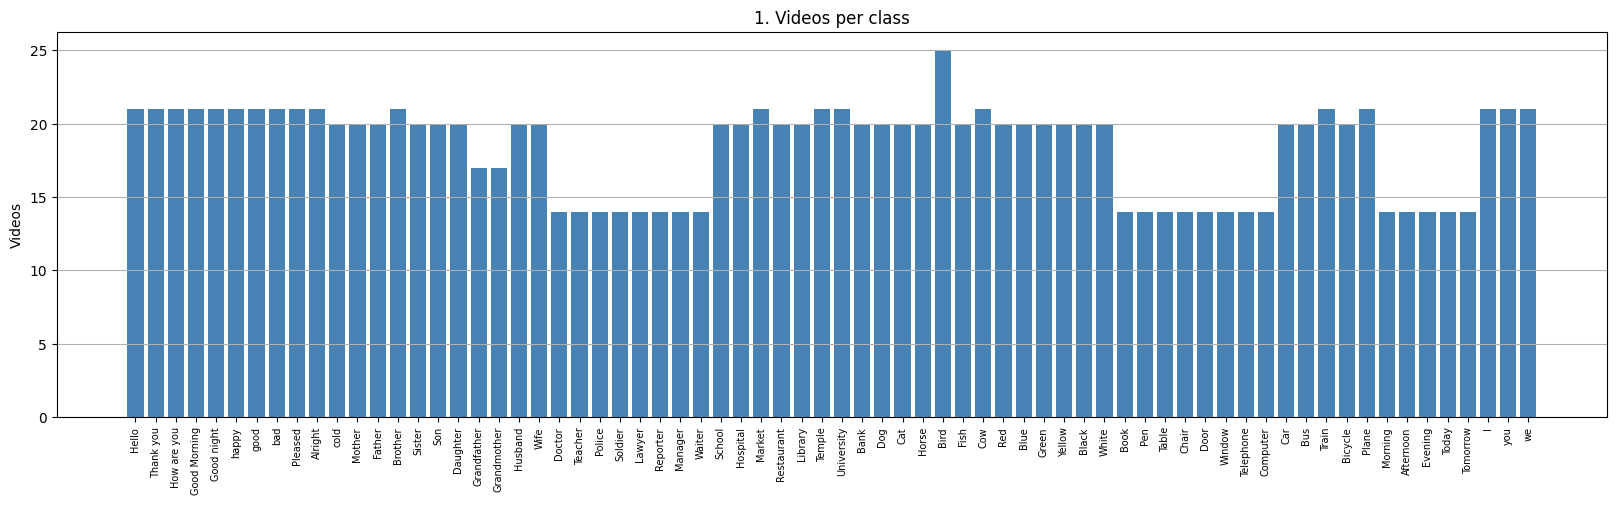

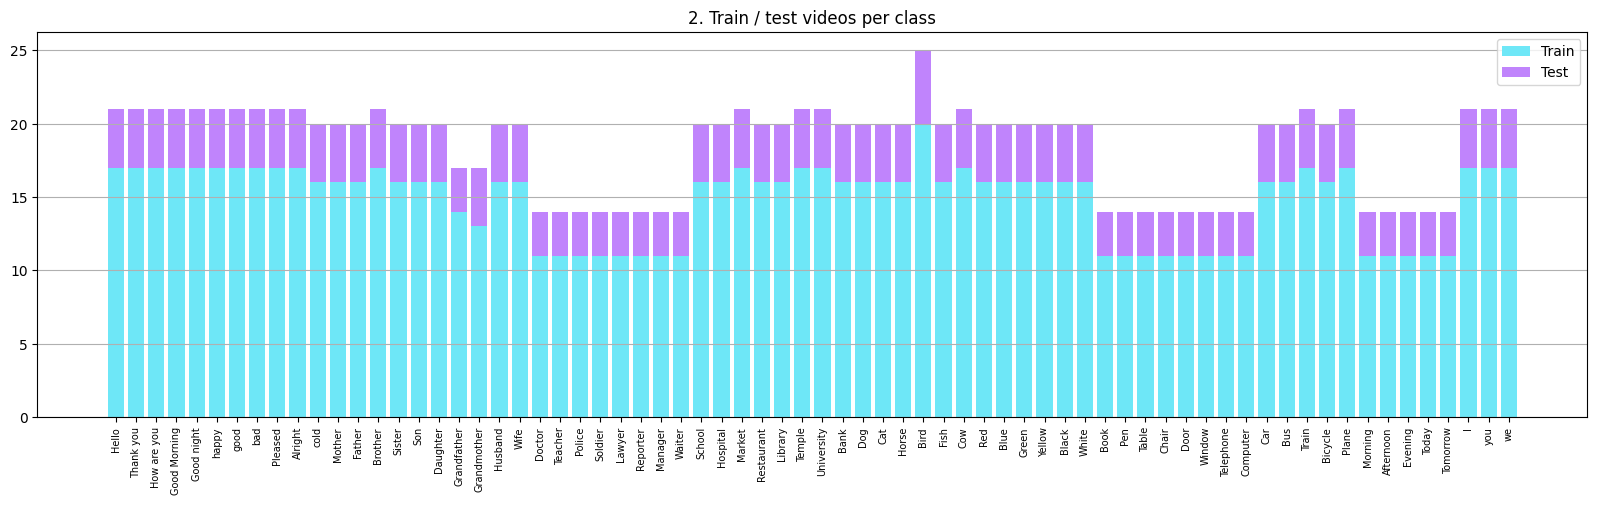

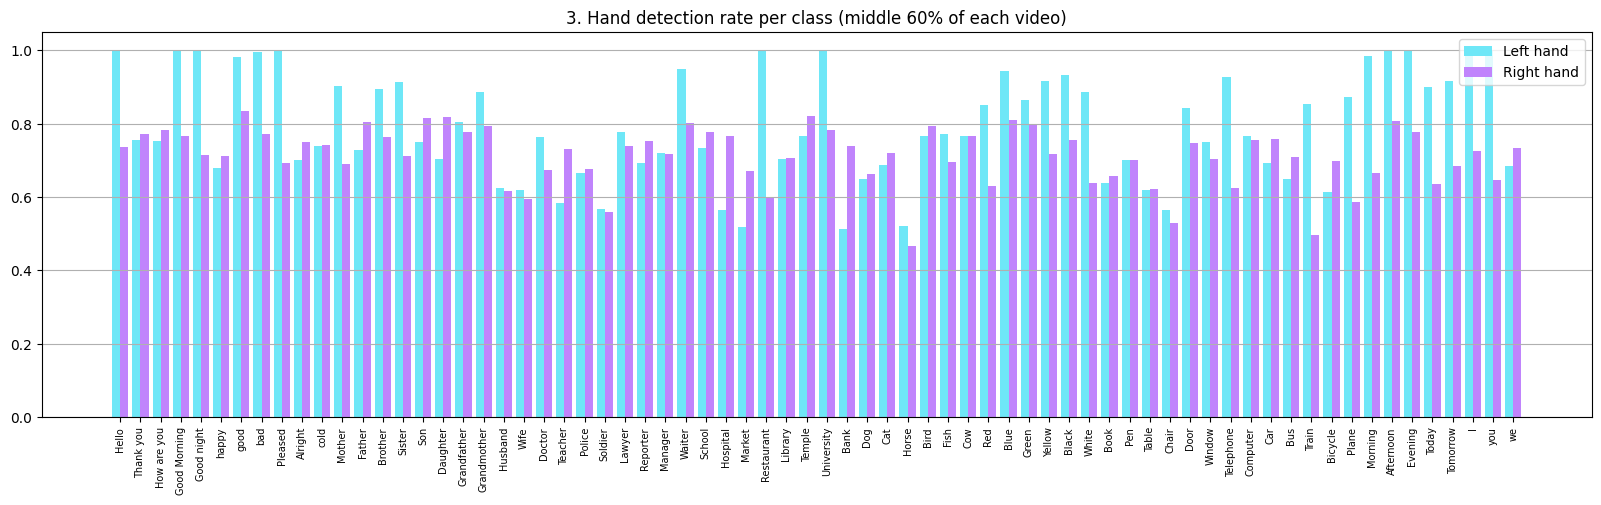

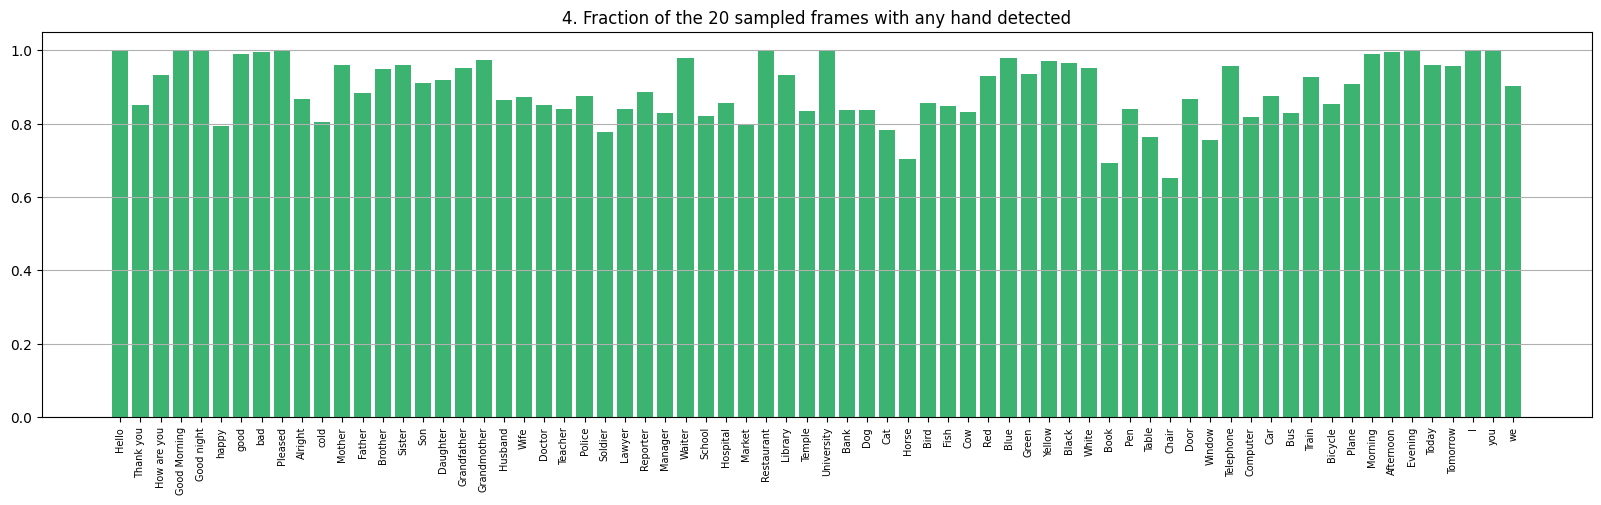

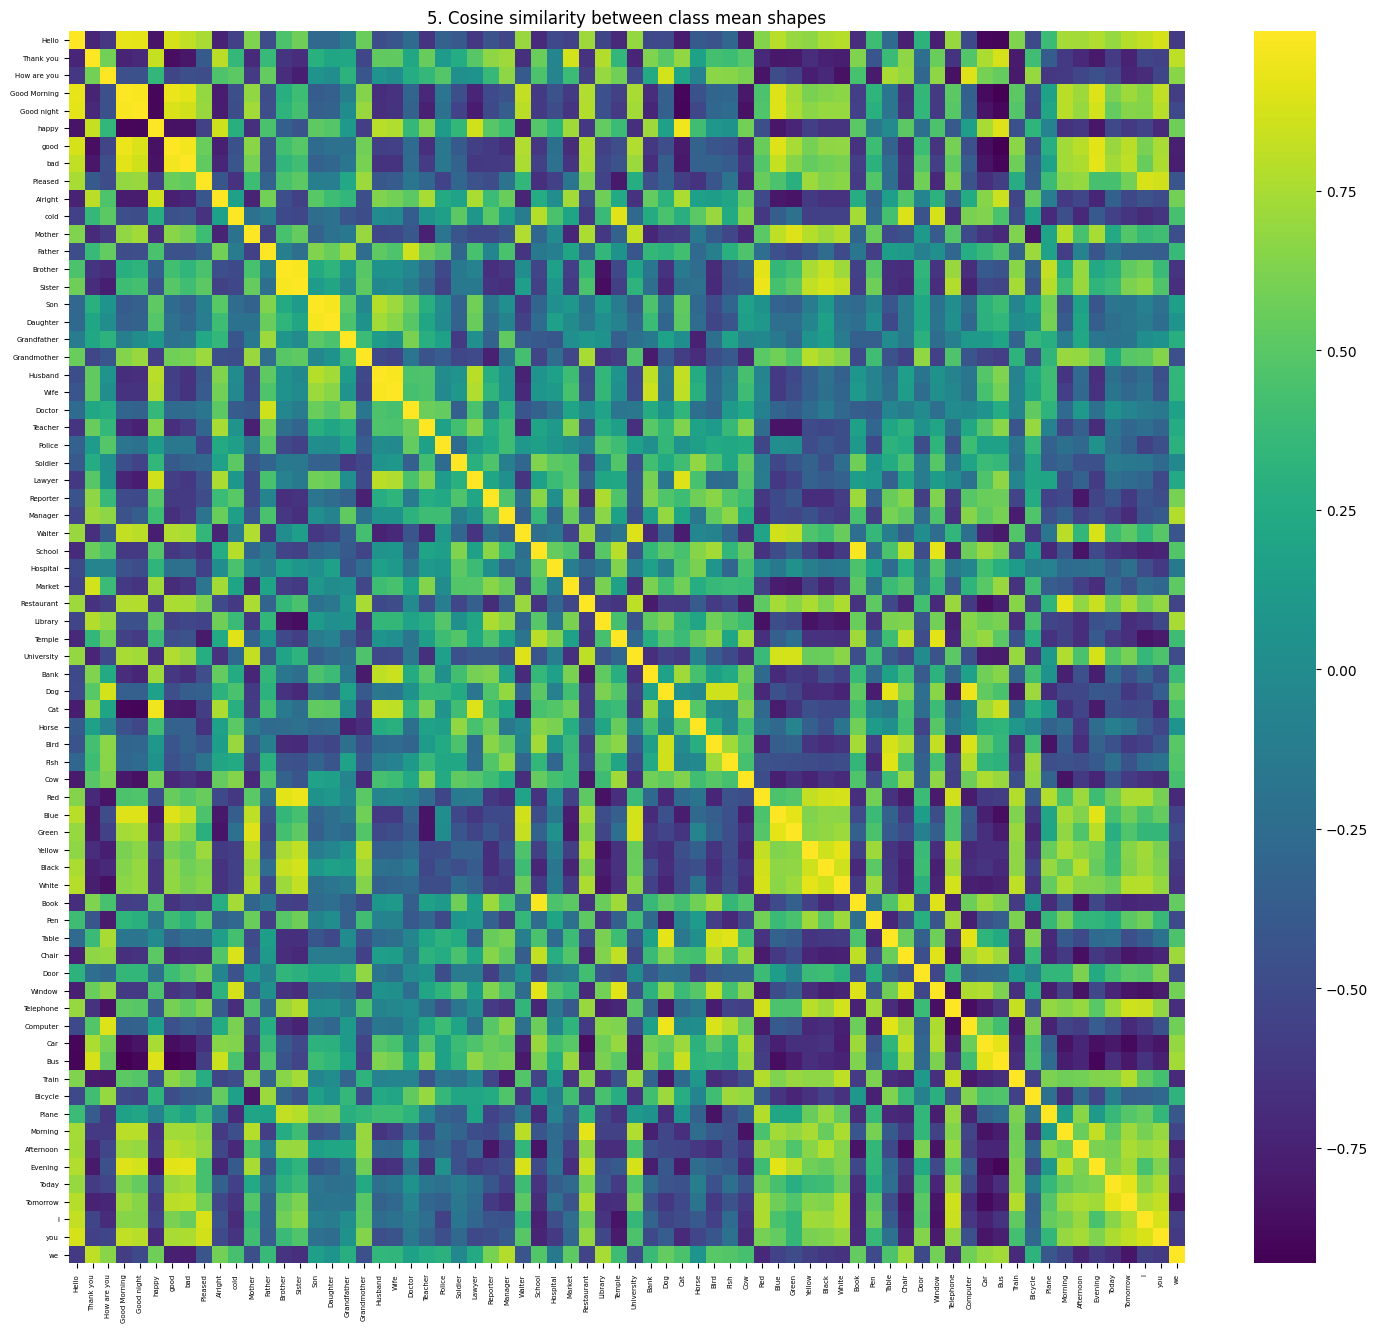

Fewest / most videos: Doctor 14 / Bird 25
Mean fraction of sampled frames with a hand: 0.894 (lowest: Chair 0.654)
Most similar class pairs:
  Husband        Wife           0.9831
  School         Book           0.9826
  Good Morning   Good night     0.9805
  Brother        Sister         0.9790
  Son            Daughter       0.9768
  good           bad            0.9667
  happy          Cat            0.9575
  Dog            Computer       0.9491
Saved: ['eda_01_videos_per_class.png', 'eda_02_train_test_split.png', 'eda_03_hand_detection.png', 'eda_04_frames_with_hand.png', 'eda_05_class_similarity.png']


In [13]:
os.makedirs('/kaggle/working/eda', exist_ok=True)
def save_fig(fig, name):
    fig.savefig(f'/kaggle/working/eda/{name}.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close(fig)

counts = np.bincount(y, minlength=NUM_CLASSES)
tr_counts = np.bincount(y[tr_idx], minlength=NUM_CLASSES)
te_counts = np.bincount(y[te_idx], minlength=NUM_CLASSES)
any_hand = (np.count_nonzero(X, axis=2) > 0)
frames_with_hand = np.array([any_hand[y == c].mean() for c in range(NUM_CLASSES)])
cmeans = np.array([X_norm[y == c].mean(axis=(0, 1)) for c in range(NUM_CLASSES)])
cn = cmeans / (np.linalg.norm(cmeans, axis=1, keepdims=True) + 1e-8)
sim = cn @ cn.T
xs = np.arange(NUM_CLASSES)

fig, ax = plt.subplots(figsize=(20, 5))
ax.bar(final_selected, counts, color='steelblue'); ax.set_title('1. Videos per class')
ax.set_ylabel('Videos'); plt.xticks(rotation=90, fontsize=7); ax.grid(True, axis='y')
save_fig(fig, 'eda_01_videos_per_class')

fig, ax = plt.subplots(figsize=(20, 5))
ax.bar(xs, tr_counts, color='#6ee7f7', label='Train'); ax.bar(xs, te_counts, bottom=tr_counts, color='#c084fc', label='Test')
ax.set_xticks(xs); ax.set_xticklabels(final_selected, rotation=90, fontsize=7)
ax.set_title('2. Train / test videos per class'); ax.legend(); ax.grid(True, axis='y')
save_fig(fig, 'eda_02_train_test_split')

fig, ax = plt.subplots(figsize=(20, 5))
ax.bar(xs - 0.2, hand_df['left_present'].values, 0.4, label='Left hand', color='#6ee7f7')
ax.bar(xs + 0.2, hand_df['right_present'].values, 0.4, label='Right hand', color='#c084fc')
ax.set_xticks(xs); ax.set_xticklabels(final_selected, rotation=90, fontsize=7)
ax.set_title('3. Hand detection rate per class (middle 60% of each video)'); ax.set_ylim(0, 1.05); ax.legend(); ax.grid(True, axis='y')
save_fig(fig, 'eda_03_hand_detection')

fig, ax = plt.subplots(figsize=(20, 5))
ax.bar(final_selected, frames_with_hand, color='mediumseagreen')
ax.set_title('4. Fraction of the 20 sampled frames with any hand detected'); ax.set_ylim(0, 1.05)
plt.xticks(rotation=90, fontsize=7); ax.grid(True, axis='y')
save_fig(fig, 'eda_04_frames_with_hand')

fig, ax = plt.subplots(figsize=(18, 16))
sns.heatmap(sim, xticklabels=final_selected, yticklabels=final_selected, cmap='viridis', ax=ax)
ax.set_title('5. Cosine similarity between class mean shapes')
plt.xticks(rotation=90, fontsize=5); plt.yticks(fontsize=5)
save_fig(fig, 'eda_05_class_similarity')

iu = np.triu_indices(NUM_CLASSES, k=1)
order = np.argsort(sim[iu])[::-1][:8]
print("Fewest / most videos:", final_selected[counts.argmin()], counts.min(), "/", final_selected[counts.argmax()], counts.max())
print(f"Mean fraction of sampled frames with a hand: {frames_with_hand.mean():.3f} "
      f"(lowest: {final_selected[frames_with_hand.argmin()]} {frames_with_hand.min():.3f})")
print("Most similar class pairs:")
for k in order:
    print(f"  {final_selected[iu[0][k]]:<14} {final_selected[iu[1][k]]:<14} {sim[iu][k]:.4f}")
print("Saved:", sorted(os.listdir('/kaggle/working/eda')))

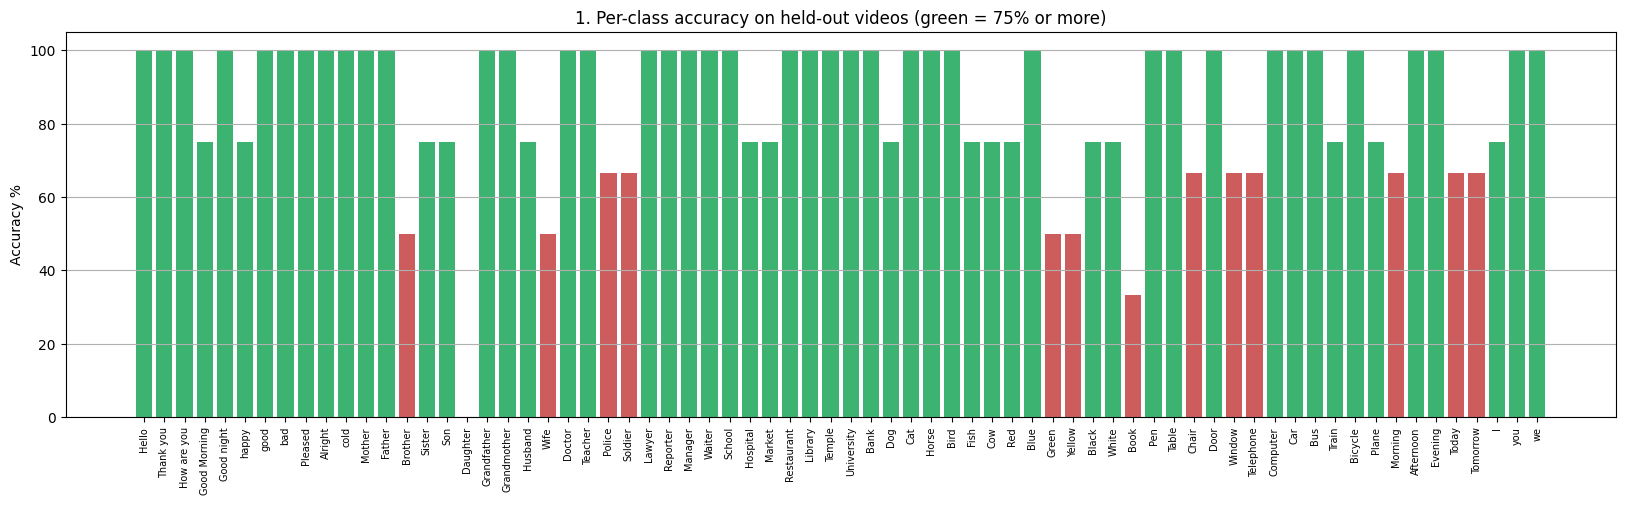

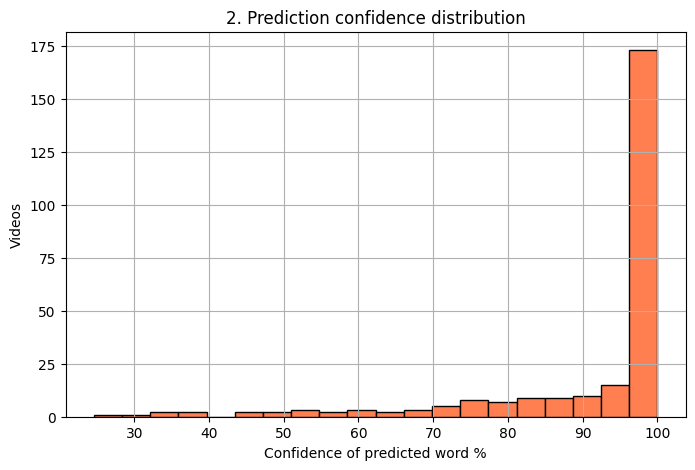

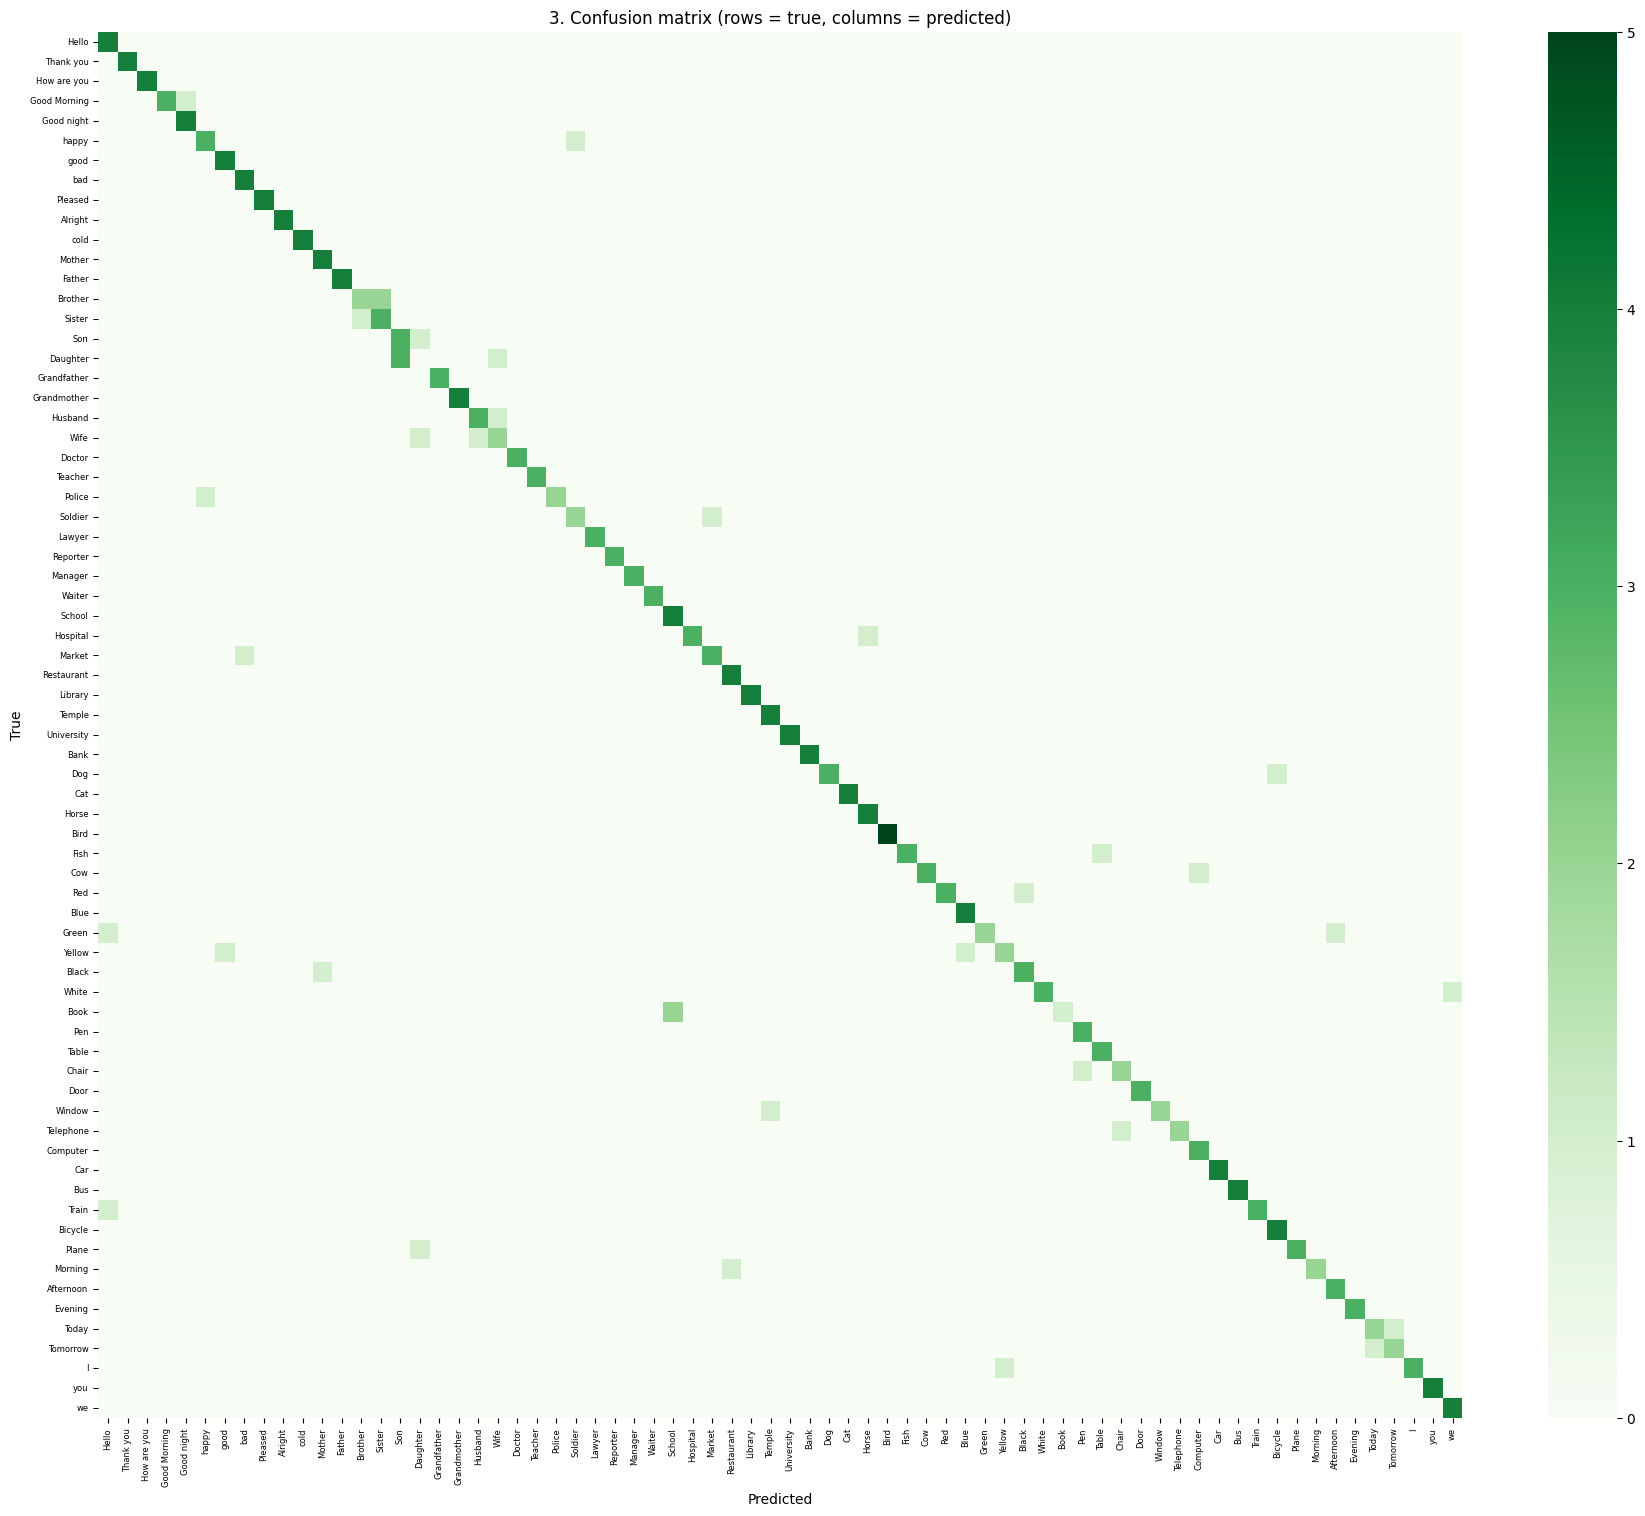

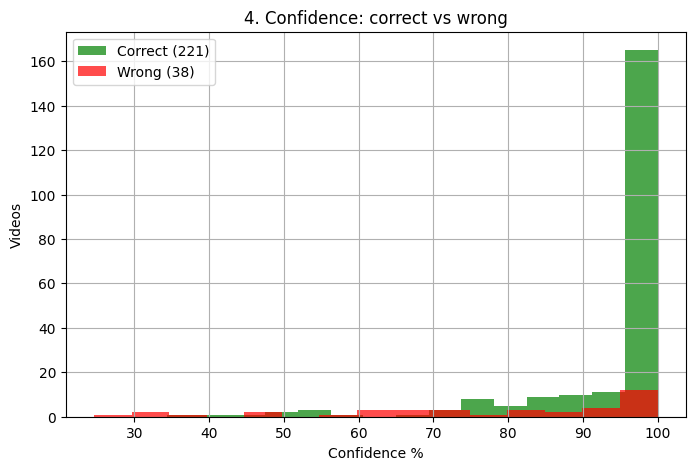

Test accuracy: 85.3282% (221/259 videos)
Macro F1: 0.849025 | classes with F1 >= 0.75: 58/70
Mean confidence when right: 94.32% | when wrong: 77.26%
Wrong predictions with confidence above 90%: 15 of 38
Most confused pairs (true -> predicted, count):
  Daughter       -> Son            3
  Brother        -> Sister         2
  Book           -> School         2
  happy          -> Soldier        1
  Yellow         -> good           1
  Yellow         -> Blue           1
  Window         -> Temple         1
  Wife           -> Husband        1
  Wife           -> Daughter       1
  White          -> we             1
Lowest-accuracy classes: [('Daughter', 0.0), ('Book', 33.3), ('Wife', 50.0), ('Brother', 50.0), ('Green', 50.0), ('Yellow', 50.0), ('Soldier', 66.7), ('Police', 66.7)]
Saved: ['analysis_01_per_class_accuracy.png', 'analysis_02_confidence_distribution.png', 'analysis_03_confusion_matrix.png', 'analysis_04_correct_vs_wrong.png', 'mlp_handaug_report.csv']


In [14]:
os.makedirs('/kaggle/working/analysis', exist_ok=True)
def save_fig(fig, name):
    fig.savefig(f'/kaggle/working/analysis/{name}.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close(fig)

probs = mlp.predict(X_test, verbose=0)
y_pred = np.argmax(probs, axis=1)
y_true = np.argmax(y_test, axis=1)
conf = probs.max(axis=1) * 100
ok = y_pred == y_true
xs = np.arange(NUM_CLASSES)

per_class = np.array([np.mean(y_pred[y_true == c] == c) for c in range(NUM_CLASSES)])
prec, rec, f1, sup = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0)
pd.DataFrame({'class': final_selected, 'precision': prec, 'recall': rec,
              'f1': f1, 'support': sup}).to_csv('/kaggle/working/analysis/mlp_handaug_report.csv', index=False)

fig, ax = plt.subplots(figsize=(20, 5))
ax.bar(xs, per_class * 100, color=np.where(per_class >= 0.75, 'mediumseagreen', 'indianred'))
ax.set_xticks(xs); ax.set_xticklabels(final_selected, rotation=90, fontsize=7)
ax.set_ylabel('Accuracy %'); ax.set_ylim(0, 105); ax.grid(True, axis='y')
ax.set_title('1. Per-class accuracy on held-out videos (green = 75% or more)')
save_fig(fig, 'analysis_01_per_class_accuracy')

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(conf, bins=20, color='coral', edgecolor='black')
ax.set_xlabel('Confidence of predicted word %'); ax.set_ylabel('Videos'); ax.grid(True)
ax.set_title('2. Prediction confidence distribution')
save_fig(fig, 'analysis_02_confidence_distribution')

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(22, 18))
sns.heatmap(cm, xticklabels=final_selected, yticklabels=final_selected, cmap='Greens', ax=ax)
ax.set_title('3. Confusion matrix (rows = true, columns = predicted)')
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.xticks(rotation=90, fontsize=6); plt.yticks(fontsize=6)
save_fig(fig, 'analysis_03_confusion_matrix')

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(conf[ok], bins=15, alpha=0.7, color='green', label=f'Correct ({ok.sum()})')
ax.hist(conf[~ok], bins=15, alpha=0.7, color='red', label=f'Wrong ({(~ok).sum()})')
ax.set_xlabel('Confidence %'); ax.set_ylabel('Videos'); ax.legend(); ax.grid(True)
ax.set_title('4. Confidence: correct vs wrong')
save_fig(fig, 'analysis_04_correct_vs_wrong')

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], final_selected[i], final_selected[j])
                for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0], reverse=True)
print(f"Test accuracy: {ok.mean()*100:.4f}% ({ok.sum()}/{len(ok)} videos)")
print(f"Macro F1: {f1.mean():.6f} | classes with F1 >= 0.75: {int((f1 >= 0.75).sum())}/{NUM_CLASSES}")
print(f"Mean confidence when right: {conf[ok].mean():.2f}% | when wrong: {conf[~ok].mean():.2f}%")
print(f"Wrong predictions with confidence above 90%: {int(((~ok) & (conf > 90)).sum())} of {int((~ok).sum())}")
print("Most confused pairs (true -> predicted, count):")
for count, t, p in pairs[:10]:
    print(f"  {t:<14} -> {p:<14} {count}")
print("Lowest-accuracy classes:",
      [(final_selected[i], round(float(per_class[i]) * 100, 1)) for i in np.argsort(per_class)[:8]])
print("Saved:", sorted(os.listdir('/kaggle/working/analysis')))

In [15]:
from importlib import metadata
import sys

def ver(*names):
    for n in names:
        try:
            return n, metadata.version(n)
        except metadata.PackageNotFoundError:
            continue
    return names[0], None

model_pkgs = [('tensorflow',), ('keras',), ('numpy',), ('h5py',), ('ml-dtypes', 'ml_dtypes'),
              ('protobuf',), ('absl-py', 'absl_py'), ('flatbuffers',), ('optree',), ('tensorboard',),
              ('scikit-learn', 'scikit_learn'), ('pandas',), ('scipy',), ('matplotlib',), ('seaborn',),
              ('Pillow', 'pillow'), ('opencv-python', 'opencv-python-headless'), ('mediapipe',)]

lines, missing = [], []
for names in model_pkgs:
    n, v = ver(*names)
    (lines if v else missing).append(f"{n}=={v}" if v else n)

header = [f"# Generated from the Kaggle notebook environment",
          f"# Python {sys.version.split()[0]}",
          "# Models were saved with the tensorflow/keras versions below; load them with the same pair.", ""]
flask_section = ["", "# Flask app packages: not installed on Kaggle, so versions are NOT filled in here.",
                 "# On your machine run:  pip freeze | findstr /i \"flask googletrans gtts dotenv werkzeug\"",
                 "# and paste the exact lines under this comment: flask, flask-cors, python-dotenv, googletrans, gTTS, werkzeug"]

with open('/kaggle/working/requirements_notebook.txt', 'w') as f:
    f.write("\n".join(header + lines + flask_section) + "\n")

print(open('/kaggle/working/requirements_notebook.txt').read())
print("Not found in this environment:", missing)
print("Loaded-model check -> tensorflow", tf.__version__, "| keras", tf.keras.__version__)

# Generated from the Kaggle notebook environment
# Python 3.13.15
# Models were saved with the tensorflow/keras versions below; load them with the same pair.

tensorflow==2.20.0
keras==3.13.2
numpy==2.1.3
h5py==3.16.0
ml-dtypes==0.6.0
protobuf==5.29.5
absl-py==2.5.0
flatbuffers==25.12.19
optree==0.20.0
tensorboard==2.20.0
scikit-learn==1.6.1
pandas==2.3.3
scipy==1.16.3
matplotlib==3.10.0
seaborn==0.13.2
Pillow==12.3.0
opencv-python==4.14.0.94
mediapipe==1.0.1

# Flask app packages: not installed on Kaggle, so versions are NOT filled in here.
# On your machine run:  pip freeze | findstr /i "flask googletrans gtts dotenv werkzeug"
# and paste the exact lines under this comment: flask, flask-cors, python-dotenv, googletrans, gTTS, werkzeug

Not found in this environment: []
Loaded-model check -> tensorflow 2.20.0 | keras 3.13.2


In [16]:
import zipfile, json
from IPython.display import FileLink

W = '/kaggle/working'
np.save(f'{W}/X_mlp_mean.npy', X_mean)
np.save(f'{W}/X_mlp_std.npy', X_std)
np.save(f'{W}/label_classes.npy', np.array(final_selected))
print("X_mlp_mean shape:", X_mean.shape, "| X_mlp_std shape:", X_std.shape)

shapes = {}
for c, cls in enumerate(final_selected):
    shapes[cls] = {"left": ref[c, 0].tolist() if ref_present[c, 0] else None,
                   "right": ref[c, 1].tolist() if ref_present[c, 1] else None}
json.dump(shapes, open(f'{W}/reference_shapes_70.json', 'w'))

p_one = results["one hand"][1]
cfg = {
    "model_file": os.path.basename(MODEL_PATH),
    "input_shape": list(mlp.input_shape[1:]),
    "num_classes": NUM_CLASSES,
    "classes": final_selected,
    "preprocessing": "per-hand wrist-relative normalization, resample whole sign to 20 frames with linspace, then (x - X_mlp_mean) / (X_mlp_std + 1e-8)",
    "test_accuracy_both_hands_percent": round(float(np.mean(y_pred == y_true) * 100), 4),
    "test_accuracy_one_dominant_hand_percent": round(float(np.mean(p_one == y_te) * 100), 4),
    "test_videos": int(len(y_true)),
    "note": "Checkpoint was selected on the same held-out videos, so accuracy is slightly optimistic.",
    "reference_shapes_file": "reference_shapes_70.json",
    "reference_shapes_format": "per class: left/right = 21x3 median hand shape (wrist-relative, max abs 1) from training videos only, or null if that hand is present in <50% of frames",
}
json.dump(cfg, open(f'{W}/model_config_mlp.json', 'w'), indent=2)

files = ['isl_mlp_model_70_handaug.keras', 'isl_mlp_model_70.keras', 'X_mlp_mean.npy', 'X_mlp_std.npy',
         'label_classes.npy', 'reference_shapes_70.json', 'model_config_mlp.json',
         'requirements_notebook.txt', 'mlp_classification_report.csv', 'hand_usage_per_class.csv']
files += sorted(f for f in os.listdir(W) if f.startswith('mlp_graph_'))

zip_path = f'{W}/isl_mlp_all_artifacts.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in files:
        if os.path.exists(f'{W}/{f}'):
            z.write(f'{W}/{f}', f); print("  added", f)
        else:
            print("  MISSING (not added):", f)
    for folder in ('eda', 'analysis'):
        for f in sorted(os.listdir(f'{W}/{folder}')):
            z.write(f'{W}/{folder}/{f}', f'{folder}/{f}'); print("  added", f'{folder}/{f}')

print(f"\nZip: {zip_path} | {os.path.getsize(zip_path)/1024/1024:.2f} MB")
FileLink('isl_mlp_all_artifacts.zip')

X_mlp_mean shape: (1, 1, 126) | X_mlp_std shape: (1, 1, 126)
  added isl_mlp_model_70_handaug.keras
  added isl_mlp_model_70.keras
  added X_mlp_mean.npy
  added X_mlp_std.npy
  added label_classes.npy
  added reference_shapes_70.json
  added model_config_mlp.json
  added requirements_notebook.txt
  added mlp_classification_report.csv
  added hand_usage_per_class.csv
  added mlp_graph_00_all_training.png
  added mlp_graph_01_accuracy.png
  added mlp_graph_02_loss.png
  added mlp_graph_03_lr.png
  added mlp_graph_04_gap.png
  added mlp_graph_05_val_loss.png
  added eda/eda_01_videos_per_class.png
  added eda/eda_02_train_test_split.png
  added eda/eda_03_hand_detection.png
  added eda/eda_04_frames_with_hand.png
  added eda/eda_05_class_similarity.png
  added analysis/analysis_01_per_class_accuracy.png
  added analysis/analysis_02_confidence_distribution.png
  added analysis/analysis_03_confusion_matrix.png
  added analysis/analysis_04_correct_vs_wrong.png
  added analysis/mlp_handaug_r

/kaggle/working/isl_mlp_all_artifacts.zip